In [1]:
import sys
import os

!nvcc --version
!which nvcc


nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2023 NVIDIA Corporation
Built on Mon_Apr__3_17:16:06_PDT_2023
Cuda compilation tools, release 12.1, V12.1.105
Build cuda_12.1.r12.1/compiler.32688072_0
/home/lesi-nedo/miniforge3/envs/HLT/bin/nvcc


### Setup

In [2]:
%%capture
!{sys.executable} -m pip install bitsandbytes
!{sys.executable} -m pip install -U -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!{sys.executable} -m pip install -U -q --no-deps "xformers<0.0.26" trl peft accelerate
!{sys.executable} -m pip install flash-attn --no-build-isolation
!{sys.executable} -m spacy download en_core_web_sm
!{sys.executable} -m pip install -U xformers --index-url https://download.pytorch.org/whl/cu121 # If you have cuda 12.1
#!{sys.executable} -m pip install -U xformers --index-url https://download.pytorch.org/whl/cu118 if you have cuda 11.8

In [4]:
import re
import pandas as pd
import gc
import math
import numpy as np
from sklearn.metrics import (accuracy_score,
                             classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from datasets import Dataset
import bitsandbytes as bnb
from unsloth import FastLanguageModel
import torch
from tqdm import tqdm
from trl import SFTTrainer
from transformers import TrainingArguments, pipeline



### Specifying the path or Downloading the required files

In [5]:
to_download = 0 #If you want to get from the internet the required files
try:
  from google.colab import drive
  drive.mount('/content/drive')
  dir = "/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv"
  txt_sent_sent = "/content/drive/MyDrive/HLT project/Project files/SentiWordNet_3.0.0.txt"
  txt_sent_vad = "/content/drive/MyDrive/HLT project/Project files/NRC-VAD-Lexicon.txt"

except ModuleNotFoundError:
  if not to_download:
    dir = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/sentiment_annotated_with_texts.csv"
    txt_sent_sent = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/SentiWordNet_3.0.0.txt"
    txt_sent_vad = "/home/lesi-nedo/Desktop/master/second-semester/HLT/project/NRC-VAD-Lexicon.txt"
  else:
    if not os. path. exists("sentiment_annotated_with_texts.csv?download=1"):
      !wget https://zenodo.org/records/7976208/files/sentiment_annotated_with_texts.csv?download=1
      dir = "sentiment_annotated_with_texts.csv?download=1"
    if not os. path. exists("SentiWordNet_3.0.0.txt"):
      !wget https://raw.githubusercontent.com/aesuli/SentiWordNet/master/data/SentiWordNet_3.0.0.txt
      txt_sent_sent = "SentiWordNet_3.0.0.txt"
    if not os. path. exists("NRC-VAD-Lexicon.txt"):
      !wget https://raw.githubusercontent.com/nchibana/moviearcs/master/NRC-VAD-Lexicon.txt
      txt_sent_vad = "NRC-VAD-Lexicon.txt"


### Loading the dataset and lowering the text

In [6]:
def norm_text(data):

  return data.lower()
with open(dir, 'r') as f:
  df1 = pd.read_csv(f, delimiter=',', quotechar='"')
df1 = df1.sample(frac=1, random_state=42).reset_index(drop=True)

df = df1[['true_sentiment', 'title']]
del df1
df['title'] = df['title'].map(norm_text)
df[:5]
len(df)

2291

### Spliting the dataset

In [7]:
X_train1 = list()
X_test1 = list()
X_eval = list()
test_perc = 0.20
train_perc = (1.0 - test_perc)



sentiments = ["Positive", "Neutral", "Negative"]


for sent in sentiments:
  train, test = train_test_split(
      df[df['true_sentiment'] == sent],
      train_size=1.0 - test_perc,
      test_size=test_perc,
      random_state=32,
  )
  X_train1.append(train)
  X_test1.append(test)

X_train1 = pd.concat(X_train1).sample(frac=1, random_state=56)
X_test1 = pd.concat(X_test1)
X_train1, X_eval1 = train_test_split(X_train1, train_size=0.9, test_size=0.1)

X_train1 = X_train1.sample(frac=1).reset_index(drop=True)
X_eval1 = X_eval1.sample(frac=1).reset_index(drop=True)

X_train1[:5]


,true_sentiment,title
0,Positive,uk gdp grows 03 mom in january vs 01 expected
1,Neutral,usdjpy price analysis w formations support str...
2,Neutral,boj will end ycc in 2023 but tweak this week u...
3,Neutral,german ifo business climate index improves to ...
4,Neutral,forex today busy week ahead with fed ecb rba i...


### Loading the SentiWordNet lexicons, and extracting the scores.

In [8]:

senti_word = {}
regex = '0(\.\d+)?\s0(\.\d+)?\s([a-z_\-]+#\d+\s)+'
pattern = re.compile(regex)


with open(txt_sent_sent, "r") as f:
  t = f.read()
  for si in t.split("\n"):
    if len(si) > 0 and si[0] != '#':
      matched = pattern.search(si)
      if matched:
        val = matched.group(0).split('\t')
        scor = [float(val[0]), float(val[1])]
        wors = re.split('#\d+\s?', val[2])
        wors.pop(-1)
        for wr in wors:
          senti_word[wr] = scor

df_senti = pd.DataFrame(senti_word, index=["pos_score", "negative_score"])
df_senti[:5]

,able,unable,dorsal,abaxial,ventral,adaxial,acroscopic,basiscopic,abducting,abducent,...,take_fire,conflagrate,catch_fire,flame_up,blaze_up,luminesce,shade_off,cloud_up,run_dry,fog_up
pos_score,0.25,0.125,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.000
negative_score,0.00,0.250,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0,0.125


### Loading the VAD lexicon scores

In [9]:


data = {}

with open(txt_sent_vad, "r") as f:
  t = f.read()
  for si in t.split('\n')[1:-1]:
    si_w = (si +'\t').split('\t')
    if si_w[0] != '':
      data[si_w[0]] = list(map(lambda fl: float(fl), si_w[1:-1]))
    else:
      pass

for w,v in data.items():
  if len(v) < 3:
    print(w)

df2 = pd.DataFrame(data, index=['valence', 'arousal', 'dominance'])
df2[:5]

,aaaaaaah,aaaah,aardvark,aback,abacus,abalone,abandon,abandoned,abandonment,abashed,...,zit,zodiac,zombie,zone,zoning,zoo,zoological,zoology,zoom,zucchini
valence,0.479,0.520,0.427,0.385,0.510,0.500,0.052,0.046,0.128,0.177,...,0.337,0.594,0.214,0.531,0.417,0.76,0.667,0.568,0.490,0.510
arousal,0.606,0.636,0.490,0.407,0.276,0.480,0.519,0.481,0.430,0.644,...,0.410,0.429,0.648,0.349,0.400,0.52,0.458,0.347,0.520,0.321
dominance,0.291,0.282,0.437,0.288,0.485,0.412,0.245,0.130,0.202,0.307,...,0.381,0.426,0.415,0.382,0.578,0.58,0.492,0.509,0.462,0.250


### Downloading the model

In [10]:

max_seq_length = 2048
dtype = None
load_in_4bit = True
# if  os.path.exists(f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"):
#   model_name = f"{os.getcwd()}/llama-3-8b-Instruct-bnb-4bit"
# else:
model_name = "unsloth/llama-3-8b-Instruct-bnb-4bit"



fourbit_model = [
    "unsloth/llama-3-8b-Instruct-bnb-4bit",
]
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = model_name,
    use_cache=False,
    max_seq_length = max_seq_length,
    dtype = dtype,
    load_in_4bit = load_in_4bit,
    attn_implementation="flash_attention_2"
)

==((====))==  Unsloth: Fast Llama patching release 2024.5
   \\   /|    GPU: NVIDIA GeForce RTX 4080 Laptop GPU. Max memory: 11.721 GB. Platform = Linux.
O^O/ \_/ \    Pytorch: 2.3.0. CUDA = 8.9. CUDA Toolkit = 12.1.
\        /    Bfloat16 = TRUE. Xformers = 0.0.25.post1. FA = True.
 "-____-"     Free Apache license: http://github.com/unslothai/unsloth


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


### Specifying various values for the tokenizer



In [11]:
tokenizer.model_max_length = max_seq_length
tokenizer.pad_token = tokenizer.eos_token  # use unk rather than eos token to prevent endless generation
tokenizer.pad_token_id = tokenizer.convert_tokens_to_ids(tokenizer.pad_token)
tokenizer.padding_side = 'left'
tokenizer.truncation_side = "left"


### The predict function
It uses the Hugging Face pipeline to generate text. It extracts the infered label by regex.

In [12]:
def predict(X_test, model, tokenizer):
  sent_reg = ".?([P,p]ositive|[N,n]egative|[N,n]eutral)"

  y_pred = []
  for i in tqdm(range(len(X_test))):
    prompt = X_test.iloc[i]['title']
    pipe = pipeline(task="text-generation",
                    model=model,
                    tokenizer=tokenizer,
                    max_new_tokens=4,
                    temperature=0.514,
                    return_tensors="pt",
                    truncation=True
                    )

    result = pipe(prompt, pad_token_id=pipe.tokenizer.eos_token_id, return_full_text=False, do_sample=False)
    answer_match = re.findall(sent_reg, result[0]['generated_text'])
    if len(answer_match) == 1 or (len(answer_match) == 2 and answer_match[0] == answer_match[1]):
      answer = answer_match[0].lower()
      if "positive" in answer:
        y_pred.append("Positive")
      elif "negative" in answer:
        y_pred.append("Negative")
      elif "neutral" in answer:
        y_pred.append("Neutral")
      else:
        print(f"\nWeird match: {answer}")
        y_pred.append("Unclear")
    else:
      print(f"\nNot found: {result[0]}")
      y_pred.append("Unclear")
  return y_pred

### Evaluation function
It calculates the accuracy for each label, and the classification matrix

In [13]:
def evaluate(y_true, y_pred):
  labels = [sent.lower() for sent in sentiments]
  mapping = {sentiments[0]: 2, sentiments[1]: 1, "Unclear": 1, sentiments[2]: 0}
  labels_map = {0: sentiments[0], 1: sentiments[1], 2: sentiments[2]}

  def map_func(x):
    return mapping.get(x, 1)

  y_true = np.vectorize(map_func)(y_true)
  y_pred = np.vectorize(map_func)(y_pred)

  accuracy = accuracy_score(y_true=y_true, y_pred=y_pred)
  print(f"Accuracy: {accuracy:.3f}")

  unique_labels = set(y_true)

  for label in unique_labels:
    label_indeces = [i for i in range(len(y_true))
                      if y_true[i] == label]
    label_y_true = [y_true[i] for i in label_indeces]
    label_y_pred = [y_pred[i] for i in label_indeces]
    accuracy = accuracy_score(label_y_true, label_y_pred)
    print(f"Accuracy for label {labels_map[label]}: {accuracy:.3f}")

  class_report = classification_report(y_true=y_true, y_pred=y_pred)
  print("\nClassification Report:")
  print(class_report)

  conf_matrix = confusion_matrix(y_true=y_true, y_pred=y_pred, labels=[0,1,2])
  print("\nConfusion Matrix:")
  disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=sentiments)
  disp.plot()

### Prompt generating
It generates the prompt for the train, eval set (with label) and for the test

In [14]:

def get_sentiment_vad(text):
  text_split = text.split(" ")
  total_score = [0, 0, 0]
  added = 1
  for word in text_split:
    if word in df2:
      total_score[0] += df2[word]['valence']
      total_score[1] += df2[word]['arousal']
      total_score[2] += df2[word]['dominance']
      added += 1
  return np.array(total_score) / added

def get_sentiment(text):
  text_split = text.split(" ")
  total_score = [0, 0]
  added = 1
  for i,word in enumerate(text_split):
    if word in df_senti:
      added += 1
      total_score[0] += df_senti[word]['pos_score']
      total_score[1] += df_senti[word]['negative_score']
    if i > 1:
      if text_split[i-1] + "_" + word in df_senti:
        total_score[0] += df_senti[text_split[i-1] + "_"+word]["pos_score"]
        total_score[1] += df_senti[text_split[i-1] + "_"+word]["negative_score"]
        added += 1

  return np.array(total_score) / added


text="""I need you to function as a sentiment analysis model that has been trained specifically on financial headlines. You will be provided with a headline enclosed in square brackets and sentiment scores, and it is your responsibility to classify
the sentiment of the headline enclosed in the square brackets accurately based on the words and provided scores.
These scores are fundamental to accurately predict the sentiment conveyed by the headline: valence score {:.5f}, arousal score {:.5f}, dominance score {:.5f}, positive SentiWordNet score {:.5f}, negative positive SentiWordNet score {:.5f}.
It is imperative to keep in mind the direct correlation between the words.
Headline: [{}]
\n\nThe response must be
\n or Positive,
\n or Negative,
\n or Neutral.
\n\nSolution: the correct option is""".strip()


def formatting_prompts_func(examples):
    all_words = set()
    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format(score_vad[0], score_vad[1], score_vad[2], score[0], score[1], examples['title']) + " " +  f"{examples['true_sentiment']}"




def formatting_prompts_func_test(examples):

    all_words = set()


    score = get_sentiment(examples["title"])
    score_vad = get_sentiment_vad(examples["title"])


    return text.format(score_vad[0], score_vad[1], score_vad[2], score[0], score[1],  examples['title'])



torch.backends.cuda.enable_mem_efficient_sdp(False)
torch.backends.cuda.enable_flash_sdp(False)

X_train = pd.DataFrame(X_train1.apply(formatting_prompts_func, axis=1), columns=['title'])
X_eval = pd.DataFrame(X_eval1.apply(formatting_prompts_func, axis=1), columns=['title'])
y_true = X_test1.true_sentiment
X_test = pd.DataFrame(X_test1.apply(formatting_prompts_func_test, axis=1), columns=['title'])

train_data = Dataset.from_pandas(X_train)
eval_data = Dataset.from_pandas(X_eval)
len(train_data)

1648

In [15]:
X_train[:1]['title'].to_numpy()

array(['I need you to function as a sentiment analysis model that has been trained specifically on financial headlines. You will be provided with a headline enclosed in square brackets and sentiment scores, and it is your responsibility to classify\nthe sentiment of the headline enclosed in the square brackets accurately based on the words and provided scores.\nThese scores are fundamental to accurately predict the sentiment conveyed by the headline: valence score 0.55200, arousal score 0.24933, dominance score 0.39467, positive SentiWordNet score 0.12500, negative positive SentiWordNet score 0.01786.\nIt is imperative to keep in mind the direct correlation between the words.\nHeadline: [uk gdp grows 03 mom in january vs 01 expected]\n\n\nThe response must be\n\n or Positive,\n\n or Negative,\n\n or Neutral.\n\n\nSolution: the correct option is Positive'],
      dtype=object)

### Zero-shot prediction on test set

In [16]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [02:09<00:00,  3.56it/s]


Accuracy: 0.688
Accuracy for label Positive: 0.739
Accuracy for label Neutral: 0.816
Accuracy for label Negative: 0.506

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.74      0.74       142
           1       0.59      0.82      0.69       163
           2       0.85      0.51      0.63       154

    accuracy                           0.69       459
   macro avg       0.73      0.69      0.69       459
weighted avg       0.72      0.69      0.68       459


Confusion Matrix:


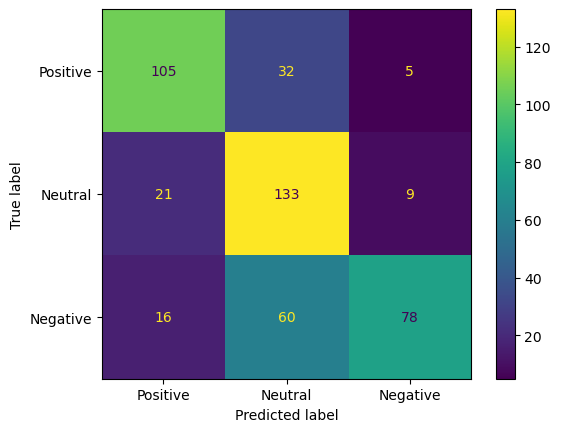

In [17]:
evaluate(y_true, y_pred)

### Geting the model with various setting

In [18]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 32,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                    "gate_proj", "up_proj", "down_proj",],

    lora_alpha = 32,
    lora_dropout = 0.3,
    bias = "none",
    use_gradient_checkpointing = True,
    random_state = 42,
    use_rslora = True,
    loftq_config = None,
)

Unsloth: Dropout = 0 is supported for fast patching. You are using dropout = 0.3.
Unsloth will patch all other layers, except LoRA matrices, causing a performance hit.
Unsloth 2024.5 patched 32 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


### Training configuration

In [21]:
training_config = {

    "do_train": True,
    "learning_rate": 1.0e-4,
    "log_level": "info",
    "logging_steps": 10,
    "logging_strategy": "steps",
    "lr_scheduler_type": "cosine",
    "num_train_epochs": 2,
    "max_steps": -1,
    "output_dir": "./checkpoint_dir",
    "overwrite_output_dir": True,
    "per_device_train_batch_size": 2,
    "gradient_accumulation_steps": 8,
    "save_steps": 200,
    "save_total_limit": 1,
    "gradient_checkpointing": True,
    "gradient_checkpointing_kwargs":{"use_reentrant": False},
    "warmup_ratio": 0.15,
    "fp16": not torch.cuda.is_bf16_supported(),
    "bf16": torch.cuda.is_bf16_supported(),
    "optim": "adamw_bnb_8bit",
    "weight_decay": 0.001,
    "seed": 42,
    "do_eval": False,
    "eval_strategy": 'steps',
    "group_by_length":True,
    }

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_data,
    eval_dataset = eval_data,
    dataset_text_field = "title",
    max_seq_length = max_seq_length,
    dataset_num_proc = 4,
    packing = False,
    args = TrainingArguments(
      **training_config
    ),
)
model.print_trainable_parameters()


using `logging_steps` to initialize `eval_steps` to 10
PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
Map (num_proc=4): 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 184/184 [00:00<00:00, 217.78 examples/s]
Using auto half precision backend


trainable params: 83,886,080 || all params: 8,114,147,328 || trainable%: 1.0338


### Training

In [22]:
trainer_stats = trainer.train()

Step,Training Loss,Validation Loss
10,1.236600,0.576358
20,0.502400,0.469456
30,0.523400,0.481343
40,0.465700,0.441755
50,0.364200,0.469925
60,0.502300,0.437554
70,0.402500,0.430960
80,0.443000,0.427100
90,0.426400,0.420274
100,0.354900,0.432850


***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  Num examples = 184
  Batch size = 8
***** Running Evaluation *****
  N

### Print some metrics

In [23]:
metrics = trainer_stats.metrics
trainer.log_metrics("train", metrics)
trainer.save_metrics("train", metrics)
trainer.save_state()

***** train metrics *****
  epoch                    =        2.0
  total_flos               = 25526501GF
  train_loss               =     0.4393
  train_runtime            = 0:30:29.32
  train_samples_per_second =      1.802
  train_steps_per_second   =      0.113


### Prediction on fine-tuned model

In [24]:
FastLanguageModel.for_inference(model)
y_pred = predict(X_test, model, tokenizer)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 459/459 [02:16<00:00,  3.35it/s]


Accuracy: 0.832
Accuracy for label Positive: 0.866
Accuracy for label Neutral: 0.810
Accuracy for label Negative: 0.825

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.87      0.85       142
           1       0.77      0.81      0.79       163
           2       0.90      0.82      0.86       154

    accuracy                           0.83       459
   macro avg       0.84      0.83      0.83       459
weighted avg       0.84      0.83      0.83       459


Confusion Matrix:


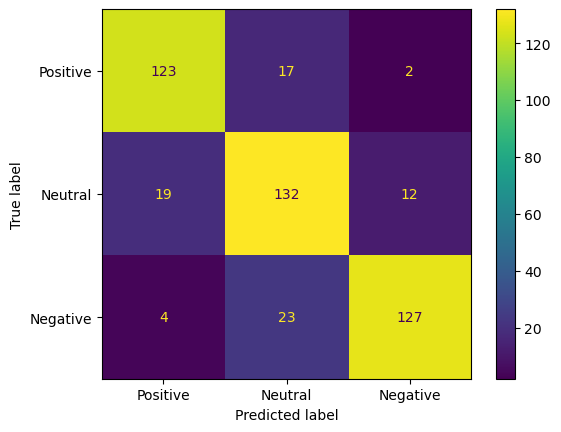

In [25]:
evaluate(y_true, y_pred)

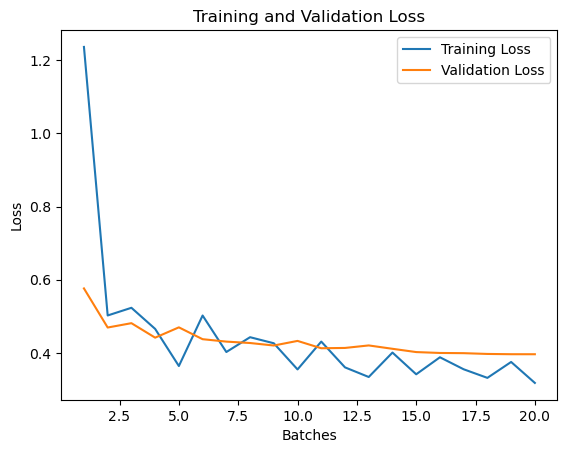

20

In [40]:
from matplotlib import pyplot as plt
train_loss = []
eval_loss = []
for elem in trainer.state.log_history:
    if 'loss' in elem.keys():
      train_loss.append(elem['loss'])
    if 'eval_loss' in elem.keys():
      eval_loss.append(elem['eval_loss'])
# # Generate a sequence of integers to represent the epoch numbers
epochs = range(1, 21)

# Plot and label the training and validation loss values
plt.plot(epochs, train_loss, label='Training Loss')
plt.plot(epochs, eval_loss, label='Validation Loss')

# Add in a title and axes labels
plt.title('Training and Validation Loss')
plt.xlabel('Batches')
plt.ylabel('Loss')

# Set the tick locations
# Display the plot
plt.legend(loc='best')
plt.show()
len(eval_loss)
# trainer.state.log_history

In [ ]:
model.save_pretrained_merged("llma3-model-fine-tuned", tokenizer)

Unsloth: Merging 4bit and LoRA weights to 16bit...
Unsloth: Will use up to 1.01 out of 14.83 RAM for saving.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:14<00:00,  2.22it/s]
tokenizer config file saved in llma3-model-fine-tuned/tokenizer_config.json
Special tokens file saved in llma3-model-fine-tuned/special_tokens_map.json
Model config LlamaConfig {
  "_name_or_path": "unsloth/llama-3-8b-Instruct-bnb-4bit",
  "architectures": [
    "LlamaForCausalLM"
  ],
  "attention_bias": false,
  "attention_dropout": 0.0,
  "bos_token_id": 128000,
  "eos_token_id": 128001,
  "hidden_act": "silu",
  "hidden_size": 4096,
  "initializer_range": 0.02,
  "intermediate_size": 14336,
  "max_position_embeddings": 8192,
  "mlp_bias": false,
  "model_type": "llama",
  "num_attention_heads": 32,
  "num_hidden_layers": 32,
  "num_key_value_heads": 8,
  "pretraining_tp": 1,
  "rms_norm_eps": 1e-05,
  "rope_scaling": null,
  "rope_theta": 500000.0,
  "tie_w

Unsloth: Saving tokenizer... Done.
Unsloth: Saving model... This might take 5 minutes for Llama-7b...
